In [ ]:

# ============================================================
# MODELO 2 — CONFIGURAÇÃO DO AMBIENTE
# ============================================================

pacotes <- c(
  "lmtest",
  "sandwich",
  "strucchange"
)

faltantes <- pacotes[
  !vapply(pacotes, requireNamespace,
          logical(1), quietly = TRUE)
]

if (length(faltantes) > 0) {
  install.packages(faltantes, repos = "https://cloud.r-project.org")
}

invisible(lapply(pacotes, library, character.only = TRUE))

cat("Pacotes carregados com sucesso.\n")


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘zoo’


Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




Pacotes carregados com sucesso.


In [ ]:
# Modelo 2 — Regra de Taylor ampliada com câmbio

Data <- seq(
  from = as.Date("2003-01-01"),
  to = as.Date("2026-07-01"),
  by = "month"
)

Selic <- c(
25.5,
26.5,
26.5,
26.5,
26.5,
26,
24.5,
22,
20,
19,
17.5,
16.5,
16.5,
16.5,
16.25,
16,
16,
16,
16,
16,
16.25,
16.75,
17.25,
17.75,
18.25,
18.75,
19.25,
19.5,
19.75,
19.75,
19.75,
19.75,
19.5,
19,
18.5,
18,
17.25,
17.25,
16.5,
15.75,
15.75,
15.25,
14.75,
14.25,
14.25,
13.75,
13.25,
13.25,
13,
13,
12.75,
12.5,
12.5,
12,
11.5,
11.5,
11.25,
11.25,
11.25,
11.25,
11.25,
11.25,
11.25,
11.75,
11.75,
12.25,
13,
13,
13.75,
13.75,
13.75,
13.75,
12.75,
12.75,
11.25,
10.25,
10.25,
9.25,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
8.75,
9.5,
9.5,
10.25,
10.75,
10.75,
10.75,
10.75,
10.75,
10.75,
11.25,
11.25,
11.75,
12,
12,
12.25,
12.5,
12.5,
12,
11.5,
11.5,
11,
10.5,
10.5,
9.75,
9,
8.5,
8.5,
8,
7.5,
7.5,
7.25,
7.25,
7.25,
7.25,
7.25,
7.25,
7.5,
8,
8,
8.5,
9,
9,
9.5,
10,
10,
10.5,
10.75,
10.75,
11,
11,
11,
11,
11,
11,
11.25,
11.25,
11.75,
12.25,
12.25,
12.75,
13.25,
13.25,
13.75,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14.25,
14,
14,
13.75,
13,
12.25,
12.25,
11.25,
11.25,
10.25,
9.25,
9.25,
8.25,
7.5,
7.5,
7,
7,
6.75,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6.5,
6,
5.5,
5,
5,
4.5,
4.5,
4.25,
3.75,
3.75,
3,
2.25,
2.25,
2,
2,
2,
2,
2,
2,
2,
2.75,
2.75,
3.5,
4.25,
4.25,
5.25,
6.25,
7.75,
7.75,
9.25,
9.25,
10.75,
11.75,
11.75,
12.75,
13.25,
13.25,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.75,
13.25,
12.75,
12.75,
12.25,
11.75,
11.75,
11.25,
10.75,
10.75,
10.5,
10.5,
10.5,
10.5,
10.75,
10.75,
11.25,
12.25,
13.25,
13.25,
14.25,
14.25,
14.75,
15,
15,
15,
15,
15,
15,
15,
15,
15,
14.75,
14.5,
14.5,
14.25,
14.25
)

Desvio_Inflacao <- c(
5.97,
7.35,
8.07,
8.27,
8.74,
8.07,
6.93,
6.57,
6.64,
5.48,
2.52,
0.80,
2.21,
1.19,
0.39,
-0.24,
-0.35,
0.56,
1.31,
1.68,
1.20,
1.36,
1.74,
2.10,
2.91,
2.89,
3.04,
3.57,
3.55,
2.77,
2.07,
1.52,
1.54,
1.86,
1.72,
1.19,
1.20,
1.01,
0.82,
0.13,
-0.27,
-0.47,
-0.53,
-0.66,
-0.80,
-1.24,
-1.48,
-1.36,
-1.51,
-1.48,
-1.54,
-1.50,
-1.32,
-0.81,
-0.76,
-0.32,
-0.35,
-0.38,
-0.31,
-0.04,
0.06,
0.11,
0.23,
0.54,
1.08,
1.56,
1.87,
1.67,
1.75,
1.91,
1.89,
1.40,
1.34,
1.40,
1.11,
1.03,
0.70,
0.30,
0.00,
-0.14,
-0.16,
-0.33,
-0.28,
-0.19,
0.09,
0.33,
0.67,
0.76,
0.72,
0.34,
0.10,
-0.01,
0.20,
0.70,
1.13,
1.41,
1.49,
1.51,
1.80,
2.01,
2.05,
2.21,
2.37,
2.73,
2.81,
2.47,
2.14,
2.00,
1.72,
1.34,
0.74,
0.60,
0.49,
0.42,
0.70,
0.74,
0.78,
0.95,
1.03,
1.34,
1.65,
1.81,
2.09,
1.99,
2.00,
2.20,
1.77,
1.59,
1.36,
1.34,
1.27,
1.41,
1.09,
1.18,
1.65,
1.78,
1.87,
2.02,
2.00,
2.01,
2.25,
2.09,
2.06,
1.91,
2.64,
3.20,
3.63,
3.67,
3.97,
4.39,
5.06,
5.03,
4.99,
5.43,
5.98,
6.17,
6.21,
5.86,
4.89,
4.78,
4.82,
4.34,
4.24,
4.47,
3.98,
3.37,
2.49,
1.79,
0.85,
0.26,
0.07,
-0.42,
-0.90,
-1.50,
-1.79,
-2.04,
-1.96,
-1.80,
-1.70,
-1.55,
-1.64,
-1.66,
-1.82,
-1.74,
-1.64,
-0.11,
-0.02,
-0.31,
0.03,
0.06,
-0.45,
-0.75,
-0.47,
-0.36,
0.33,
0.69,
0.41,
-0.88,
-1.03,
-0.82,
-1.36,
-1.71,
-0.98,
0.06,
0.19,
0.01,
-0.70,
-1.60,
-2.12,
-1.87,
-1.69,
-1.56,
-0.86,
-0.08,
0.31,
0.52,
0.81,
1.45,
2.35,
3.01,
4.31,
4.60,
5.24,
5.93,
6.50,
6.92,
6.99,
6.31,
6.88,
7.04,
7.80,
8.63,
8.23,
8.39,
6.57,
5.23,
3.67,
2.97,
2.40,
2.29,
2.52,
2.35,
1.40,
0.93,
0.69,
-0.09,
0.74,
1.36,
1.94,
1.57,
1.43,
1.37,
1.51,
1.50,
0.93,
0.69,
0.93,
1.23,
1.50,
1.24,
1.42,
1.76,
1.87,
1.83,
1.56,
2.06,
2.48,
2.53,
2.32,
2.35,
2.23,
2.13,
2.17,
1.68,
1.46,
1.26,
1.44,
0.81,
1.14,
1.39,
1.72,
1.64,
1.44
)

Hiato_IBC <- c(
1.3052416,
2.6465875,
1.6722098,
0.5734678,
-0.8160983,
-1.0278685,
-2.6467698,
-2.2913734,
-0.5060664,
-1.0577816,
-1.1969169,
-1.8356364,
-0.4283889,
0.2241138,
0.9311014,
1.0372742,
0.5298117,
0.9616907,
0.9561527,
1.0278880,
1.6707133,
0.5770656,
1.2898679,
0.1475142,
0.3984788,
0.6323513,
0.3907875,
0.7171827,
0.2352365,
-0.7659425,
-1.1445119,
-0.7662338,
-1.3924393,
-1.7328627,
-1.3109356,
-0.9201655,
-0.5194916,
-0.8462987,
-1.3598945,
-1.1335616,
-0.2742705,
-1.8093102,
-0.3447475,
-0.7306792,
-0.8702564,
-0.2016185,
0.1415803,
1.0127832,
0.3170972,
0.1834383,
-0.7904544,
0.1869450,
0.6893889,
0.9530807,
1.3470609,
1.2020722,
1.6678184,
2.3265451,
1.9850438,
2.5900621,
2.4538481,
1.9651758,
0.9498585,
2.1006917,
2.7826991,
3.4451727,
3.2161314,
3.1725813,
2.8918246,
0.5918618,
-2.1318951,
-5.0374809,
-5.4709800,
-4.9939830,
-4.6615849,
-4.5242400,
-3.9199017,
-3.6237033,
-3.6796335,
-2.4334034,
-1.9489245,
-1.4994952,
-1.7191362,
-0.5882019,
0.5361907,
1.1402180,
1.8631473,
2.0192152,
0.8463240,
0.2524597,
0.5315760,
0.8356598,
1.4102525,
0.9313298,
1.7556420,
0.3958084,
1.3395263,
1.4643395,
1.1807318,
0.9971690,
0.8898462,
0.9816799,
0.8824743,
0.5741358,
0.2193177,
-0.0654115,
0.1991107,
-0.9557417,
-2.3634196,
-1.6039826,
-2.0228963,
-1.7473618,
-0.7799465,
-0.2328198,
-0.2235432,
-0.0317141,
-0.5862151,
0.1149401,
-0.1436093,
-0.6820259,
-0.1353152,
-1.1723532,
-0.2585376,
0.7845191,
0.8980505,
0.5047011,
0.8394081,
1.1475600,
1.6585400,
1.6362981,
1.9536077,
2.2852373,
2.0544346,
1.8524318,
1.8356743,
1.5312693,
1.3082977,
-0.7076199,
0.2141051,
1.2794105,
2.0196946,
1.3601261,
1.7564710,
2.3980337,
1.7443185,
1.3415444,
1.4081667,
0.3038347,
-0.1197500,
-0.8211108,
-1.7381027,
-0.9797185,
-1.4414523,
-0.8383252,
-1.6061693,
-1.5844435,
-1.8311776,
-1.7597364,
-2.2563672,
-2.1196450,
-2.1825482,
-1.8493854,
-2.0276194,
-2.1378694,
-1.8556898,
-2.2717440,
-2.1047121,
-2.2850270,
-1.6440116,
-0.4090506,
-0.2672209,
-0.3794618,
-0.5817860,
0.0780806,
0.1255109,
-0.1309578,
-0.1411601,
0.0635190,
0.2476349,
1.5715514,
1.0283042,
0.6129647,
0.6065100,
1.1587883,
-1.9757255,
0.8337719,
1.1315340,
1.9071469,
1.3128568,
1.6288974,
1.9123351,
2.1909511,
1.9496380,
1.3544626,
0.7204399,
0.6820281,
2.0890652,
1.5289371,
1.3165705,
1.5713695,
1.8970344,
3.0835944,
2.9056377,
2.5518765,
2.5444436,
2.6624477,
-4.1733188,
-12.9334475,
-10.3318992,
-6.3398212,
-3.9300361,
-2.1757833,
-0.3432921,
1.5676013,
1.6538928,
1.6783846,
1.6502476,
2.4376552,
-1.2665222,
-0.3865459,
0.1520734,
-0.3252018,
-0.8581112,
-0.4423841,
-0.7128944,
-0.3907805,
0.9867867,
1.0923417,
-1.1341192,
-0.2823530,
0.5611475,
0.2100004,
0.1551055,
-0.2370702,
1.4368170,
0.8674937,
0.6675293,
0.6931709,
-0.2746817,
-0.6526117,
-1.3847053,
1.2932281,
1.0464734,
1.6040360,
-0.1231288,
-0.4119058,
-0.1666912,
-0.8090401,
-1.0401254,
-0.9724090,
-0.4963925,
0.4904409,
-0.1775805,
-0.2382589,
-0.4591732,
-0.7631521,
-0.0900286,
0.5928752,
0.8280124,
0.7094564,
1.2785972,
1.2489439,
0.7946515,
-0.0263501,
0.3853477,
0.6534167,
1.7897059,
1.1066443,
0.3217666,
0.0636052,
-0.3380271,
-0.3130861,
-0.6213202,
-0.7900172,
-0.5094758,
-0.4949934,
-0.0681777,
0.3552499,
0.0180575,
0.1808615,
0.1841096,
-0.7878464,
-1.2757365
)

Variacao_Cambio <- c(
-0.0530963,
0.0433688,
-0.0408997,
-0.1000590,
-0.0536807,
-0.0248347,
-0.0011799,
0.0417244,
-0.0269032,
-0.0211961,
0.0181121,
0.0039390,
-0.0254467,
0.0271544,
-0.0084993,
0.0001721,
0.0647536,
0.0092143,
-0.0299411,
-0.0112258,
-0.0379414,
-0.0133010,
-0.0237291,
-0.0246370,
-0.0093141,
-0.0359909,
0.0403261,
-0.0475117,
-0.0502490,
-0.0161523,
-0.0167123,
-0.0054498,
-0.0284445,
-0.0166564,
-0.0204605,
0.0332304,
-0.0050884,
-0.0505090,
-0.0045898,
-0.0106044,
0.0226596,
0.0317214,
-0.0265925,
-0.0153736,
0.0059196,
-0.0094511,
0.0044587,
-0.0037142,
-0.0053167,
-0.0199308,
-0.0036320,
-0.0275213,
-0.0251159,
-0.0254006,
-0.0257439,
0.0432410,
-0.0343577,
-0.0533013,
-0.0174190,
0.0090554,
-0.0065725,
-0.0266149,
-0.0117022,
-0.0110114,
-0.0169587,
-0.0253719,
-0.0171328,
0.0130476,
0.1099027,
0.1884983,
0.0420859,
0.0549841,
-0.0370113,
0.0022943,
0.0004755,
-0.0477556,
-0.0679928,
-0.0514235,
-0.0127495,
-0.0463821,
-0.0138611,
-0.0457615,
-0.0070427,
0.0138647,
0.0167138,
0.0341338,
-0.0307683,
-0.0164864,
0.0317131,
-0.0037020,
-0.0206377,
-0.0056670,
-0.0235183,
-0.0206932,
0.0175464,
-0.0116830,
-0.0109849,
-0.0041282,
-0.0053500,
-0.0448080,
0.0169384,
-0.0165603,
-0.0146627,
0.0209442,
0.0913746,
0.0129459,
0.0100475,
0.0255845,
-0.0260314,
-0.0406544,
0.0437785,
0.0326047,
0.0683457,
0.0313269,
-0.0100543,
0.0003450,
-0.0006408,
0.0008379,
0.0185480,
0.0048244,
-0.0227321,
-0.0288703,
0.0048027,
0.0097366,
0.0161510,
0.0657112,
0.0357988,
0.0391831,
-0.0310906,
-0.0367380,
0.0476451,
0.0215915,
0.0155258,
0.0006295,
-0.0244609,
-0.0409366,
-0.0053439,
0.0065524,
-0.0048878,
0.0193213,
0.0282137,
0.0482818,
0.0400718,
0.0350859,
-0.0019721,
0.0669154,
0.1085686,
-0.0311540,
0.0060607,
0.0161989,
0.0351744,
0.0864967,
0.1058015,
-0.0067809,
-0.0270633,
0.0247410,
0.0457706,
-0.0196116,
-0.0703113,
-0.0379979,
-0.0074595,
-0.0329735,
-0.0444544,
-0.0203236,
0.0144448,
-0.0219189,
0.0478660,
0.0030772,
-0.0475589,
-0.0293317,
0.0076058,
0.0026500,
0.0231033,
0.0264124,
-0.0274723,
-0.0173671,
-0.0051228,
0.0178316,
0.0211461,
0.0099218,
-0.0250071,
0.0095784,
0.0115633,
0.0383794,
0.0649328,
0.0370118,
0.0146280,
0.0260371,
0.0464148,
-0.0910100,
0.0075016,
0.0256538,
-0.0376087,
-0.0048491,
0.0324727,
0.0128381,
0.0266676,
-0.0363130,
-0.0208174,
0.0617431,
0.0249353,
-0.0084060,
0.0165734,
-0.0110589,
0.0096621,
0.0451169,
0.1178393,
0.0865813,
0.0579613,
-0.0824822,
0.0159594,
0.0337046,
-0.0113622,
0.0410568,
-0.0376733,
-0.0515478,
0.0401128,
0.0111951,
0.0415152,
-0.0149893,
-0.0499496,
-0.0502285,
0.0244992,
0.0182550,
0.0053174,
0.0481252,
0.0030459,
0.0168629,
-0.0209744,
-0.0629244,
-0.0449067,
-0.0432704,
0.0405899,
0.0188125,
0.0612442,
-0.0427791,
0.0180539,
0.0025364,
0.0046366,
-0.0061424,
-0.0079862,
-0.0055918,
0.0076663,
-0.0374976,
-0.0073782,
-0.0266834,
-0.0105260,
0.0211667,
0.0068086,
0.0255568,
-0.0334264,
-0.0002246,
0.0035061,
0.0101228,
0.0031575,
0.0294802,
0.0007601,
0.0486696,
0.0279956,
0.0019108,
-0.0019830,
0.0147777,
0.0320204,
0.0487155,
-0.0124106,
-0.0434770,
-0.0032660,
0.0064004,
-0.0203132,
-0.0214552,
-0.0033587,
-0.0148699,
-0.0147030,
0.0033665,
-0.0083160,
0.0207901,
-0.0213332,
-0.0260770,
0.0059432,
-0.0386811,
-0.0098635,
0.0284651,
-0.0026754
)

# Construção da base
base <- data.frame(
  Data,
  Selic,
  Desvio_Inflacao,
  Hiato_IBC,
  Variacao_Cambio
)

# Verificação inicial
dim(base)
summary(base)# Modelo 2 — Regra de Taylor ampliada com câmbio


[1] 283   5

      Data                Selic       Desvio_Inflacao    Hiato_IBC         
 Min.   :2003-01-01   Min.   : 2.00   Min.   :-2.120   Min.   :-12.933447  
 1st Qu.:2008-11-16   1st Qu.: 8.75   1st Qu.: 0.080   1st Qu.: -0.799747  
 Median :2014-10-01   Median :11.75   Median : 1.400   Median :  0.186945  
 Mean   :2014-10-01   Mean   :11.69   Mean   : 1.645   Mean   : -0.006912  
 3rd Qu.:2020-08-16   3rd Qu.:14.25   3rd Qu.: 2.305   3rd Qu.:  1.191402  
 Max.   :2026-07-01   Max.   :26.50   Max.   : 8.740   Max.   :  3.445173  
 Variacao_Cambio    
 Min.   :-0.100059  
 1st Qu.:-0.021687  
 Median :-0.002675  
 Mean   : 0.001215  
 3rd Qu.: 0.021045  
 Max.   : 0.188498  

In [ ]:

# ============================================================
# MODELO 2 — CONSTRUÇÃO E VALIDAÇÃO DA BASE
# ============================================================

base_m2 <- data.frame(
  Data = Data,
  Selic = Selic,
  Desvio_Inflacao = Desvio_Inflacao,
  Hiato_IBC = Hiato_IBC,
  Variacao_Cambio = Variacao_Cambio
)

base_m2 <- base_m2[order(base_m2$Data), ]

stopifnot(
  nrow(base_m2) == 283,
  length(unique(base_m2$Data)) == 283,
  identical(base_m2$Data,
            seq(as.Date("2003-01-01"),
                as.Date("2026-07-01"),
                by = "month")),
  all(complete.cases(base_m2)),
  all(is.finite(as.matrix(base_m2[, -1])))
)

# Defasagem de um mês nas variáveis explicativas
dados_modelo2 <- data.frame(
  Data = base_m2$Data[-1],
  Selic = base_m2$Selic[-1],
  Selic_L1 = head(base_m2$Selic, -1),
  Desvio_Inflacao_L1 = head(base_m2$Desvio_Inflacao, -1),
  Hiato_IBC_L1 = head(base_m2$Hiato_IBC, -1),
  Variacao_Cambio_L1 = head(base_m2$Variacao_Cambio, -1)
)

stopifnot(
  nrow(dados_modelo2) == 282,
  all(complete.cases(dados_modelo2)),
  min(dados_modelo2$Data) == as.Date("2003-02-01"),
  max(dados_modelo2$Data) == as.Date("2026-07-01")
)

cat("========== VALIDAÇÃO DA BASE ==========\n")
cat("Observações originais:", nrow(base_m2), "\n")
cat("Observações efetivas:", nrow(dados_modelo2), "\n")
cat("Primeiro mês:",
    format(min(dados_modelo2$Data), "%m/%Y"), "\n")
cat("Último mês:",
    format(max(dados_modelo2$Data), "%m/%Y"), "\n")

print(head(dados_modelo2, 3))
print(tail(dados_modelo2, 3))


========== VALIDAÇÃO DA BASE ==========
Observações originais: 283 
Observações efetivas: 282 
Primeiro mês: 02/2003 
Último mês: 07/2026 
        Data Selic Selic_L1 Desvio_Inflacao_L1 Hiato_IBC_L1 Variacao_Cambio_L1
1 2003-02-01  26.5     25.5               5.97     1.305242         -0.0530963
2 2003-03-01  26.5     26.5               7.35     2.646587          0.0433688
3 2003-04-01  26.5     26.5               8.07     1.672210         -0.0408997
          Data Selic Selic_L1 Desvio_Inflacao_L1 Hiato_IBC_L1
280 2026-05-01 14.50    14.50               1.39    0.1808615
281 2026-06-01 14.25    14.50               1.72    0.1841096
282 2026-07-01 14.25    14.25               1.64   -0.7878464
    Variacao_Cambio_L1
280         -0.0386811
281         -0.0098635
282          0.0284651


In [ ]:

# ============================================================
# MODELO 2 — ESTIMAÇÃO DA FUNÇÃO DE REAÇÃO
# ============================================================

formula_m2 <- Selic ~ Selic_L1 +
  Desvio_Inflacao_L1 +
  Hiato_IBC_L1 +
  Variacao_Cambio_L1

modelo2 <- lm(
  formula_m2,
  data = dados_modelo2
)

vcov_NW_m2 <- sandwich::NeweyWest(
  modelo2,
  lag = NULL,
  prewhite = FALSE,
  adjust = TRUE
)

resultado_NW_m2 <- lmtest::coeftest(
  modelo2,
  vcov. = vcov_NW_m2
)

cat("\n========== MQO — MODELO 2 ==========\n")
print(summary(modelo2))

cat("\n========== COEFICIENTES COM NEWEY-WEST ==========\n")
print(resultado_NW_m2)

cat("\n========== INDICADORES DO MODELO ==========\n")

indicadores_m2 <- c(
  Observacoes = nobs(modelo2),
  R2 = summary(modelo2)$r.squared,
  R2_Ajustado = summary(modelo2)$adj.r.squared,
  AIC = AIC(modelo2),
  BIC = BIC(modelo2)
)

print(indicadores_m2)



========== MQO — MODELO 2 ==========

Call:
lm(formula = formula_m2, data = dados_modelo2)

Residuals:
     Min       1Q   Median       3Q      Max 
-2.12474 -0.16562 -0.00668  0.23355  1.11146 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)         0.296168   0.069609   4.255 2.87e-05 ***
Selic_L1            0.960184   0.006136 156.475  < 2e-16 ***
Desvio_Inflacao_L1  0.079234   0.012019   6.593 2.18e-10 ***
Hiato_IBC_L1        0.093022   0.013136   7.082 1.18e-11 ***
Variacao_Cambio_L1 -1.002978   0.701828  -1.429    0.154    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.4143 on 277 degrees of freedom
Multiple R-squared:  0.9918,	Adjusted R-squared:  0.9917 
F-statistic:  8412 on 4 and 277 DF,  p-value: < 2.2e-16


========== COEFICIENTES COM NEWEY-WEST ==========

t test of coefficients:

                    Estimate Std. Error t value  Pr(>|t|)    
(Intercept)         0.296168   0.151070  1.

In [ ]:

# ============================================================
# MODELO 2 — PARÂMETROS ESTRUTURAIS
# ============================================================

b <- coef(modelo2)

rho <- unname(b["Selic_L1"])
denominador <- 1 - rho

if (abs(denominador) < 1e-8) {
  stop("Rho muito próximo de 1: transformação instável.")
}

parametros_m2 <- c(
  alpha = unname(b["(Intercept)"]),
  rho = rho,
  phi_pi = unname(b["Desvio_Inflacao_L1"]) / denominador,
  phi_y = unname(b["Hiato_IBC_L1"]) / denominador,
  phi_e = unname(b["Variacao_Cambio_L1"]) / denominador
)

# Jacobiana na ordem dos coeficientes de lm()
J <- matrix(
  0, nrow = 5, ncol = 5,
  dimnames = list(names(parametros_m2), names(b))
)

J["alpha", "(Intercept)"] <- 1
J["rho", "Selic_L1"] <- 1

J["phi_pi", "Selic_L1"] <-
  b["Desvio_Inflacao_L1"] / denominador^2
J["phi_pi", "Desvio_Inflacao_L1"] <- 1 / denominador

J["phi_y", "Selic_L1"] <-
  b["Hiato_IBC_L1"] / denominador^2
J["phi_y", "Hiato_IBC_L1"] <- 1 / denominador

J["phi_e", "Selic_L1"] <-
  b["Variacao_Cambio_L1"] / denominador^2
J["phi_e", "Variacao_Cambio_L1"] <- 1 / denominador

V_estrutural_m2 <- J %*% vcov_NW_m2 %*% t(J)

ep_m2 <- sqrt(diag(V_estrutural_m2))
t_m2 <- parametros_m2 / ep_m2

p_m2 <- 2 * pt(
  abs(t_m2),
  df = df.residual(modelo2),
  lower.tail = FALSE
)

tabela_estrutural_m2 <- data.frame(
  Parametro = names(parametros_m2),
  Estimativa = as.numeric(parametros_m2),
  Erro_padrao_NW = as.numeric(ep_m2),
  Estatistica_t = as.numeric(t_m2),
  Valor_p = as.numeric(p_m2)
)

stopifnot(
  all(is.finite(as.matrix(tabela_estrutural_m2[, -1]))),
  nrow(tabela_estrutural_m2) == 5
)

cat("\n========== PARÂMETROS ESTRUTURAIS — MODELO 2 ==========\n")

print(
  transform(
    tabela_estrutural_m2,
    Estimativa = round(Estimativa, 6),
    Erro_padrao_NW = round(Erro_padrao_NW, 6),
    Estatistica_t = round(Estatistica_t, 4),
    Valor_p = signif(Valor_p, 5)
  ),
  row.names = FALSE
)



========== PARÂMETROS ESTRUTURAIS — MODELO 2 ==========
 Parametro Estimativa Erro_padrao_NW Estatistica_t     Valor_p
     alpha   0.296168       0.151070        1.9605  5.0944e-02
       rho   0.960184       0.013534       70.9465 1.1093e-179
    phi_pi   1.989993       0.956458        2.0806  3.8391e-02
     phi_y   2.336284       0.828587        2.8196  5.1554e-03
     phi_e -25.190122      14.177957       -1.7767  7.6713e-02


In [ ]:

# ============================================================
# MODELO 2 — JANELAS MÓVEIS DE 84 MESES
# ============================================================

tamanho_janela <- 84
n_total <- nrow(dados_modelo2)
n_janelas <- n_total - tamanho_janela + 1

stopifnot(
  n_total == 282,
  n_janelas == 199,
  all(complete.cases(dados_modelo2))
)

estimar_janela_m2 <- function(inicio) {

  fim <- inicio + tamanho_janela - 1

  dados_janela <- dados_modelo2[inicio:fim, ]

  modelo <- lm(formula_m2, data = dados_janela)

  V <- sandwich::NeweyWest(
    modelo,
    lag = NULL,
    prewhite = FALSE,
    adjust = TRUE
  )

  teste <- lmtest::coeftest(modelo, vcov. = V)
  b <- coef(modelo)

  rho <- unname(b["Selic_L1"])
  d <- 1 - rho

  if (abs(d) < 1e-8) {
    stop("Rho próximo de 1 na janela ", inicio)
  }

  parametros <- c(
    alpha = unname(b["(Intercept)"]),
    rho = rho,
    phi_pi = unname(b["Desvio_Inflacao_L1"]) / d,
    phi_y = unname(b["Hiato_IBC_L1"]) / d,
    phi_e = unname(b["Variacao_Cambio_L1"]) / d
  )

  # Jacobiana para o método delta
  J <- matrix(
    0, nrow = 5, ncol = 5,
    dimnames = list(names(parametros), names(b))
  )

  J["alpha", "(Intercept)"] <- 1
  J["rho", "Selic_L1"] <- 1

  for (par in c(
    "Desvio_Inflacao_L1",
    "Hiato_IBC_L1",
    "Variacao_Cambio_L1"
  )) {

    nome_phi <- switch(
      par,
      Desvio_Inflacao_L1 = "phi_pi",
      Hiato_IBC_L1 = "phi_y",
      Variacao_Cambio_L1 = "phi_e"
    )

    J[nome_phi, "Selic_L1"] <- b[par] / d^2
    J[nome_phi, par] <- 1 / d
  }

  V_estrutural <- J %*% V %*% t(J)

  ep_estrutural <- sqrt(diag(V_estrutural))

  p_estrutural <- 2 * pt(
    abs(parametros / ep_estrutural),
    df = df.residual(modelo),
    lower.tail = FALSE
  )

  # Organizar resultados em uma linha por janela
  resultado <- data.frame(
    Data = max(dados_janela$Data),

    beta_selic = unname(b["Selic_L1"]),
    beta_inflacao = unname(b["Desvio_Inflacao_L1"]),
    beta_hiato = unname(b["Hiato_IBC_L1"]),
    beta_cambio = unname(b["Variacao_Cambio_L1"]),

    ep_beta_selic = teste["Selic_L1", 2],
    ep_beta_inflacao = teste["Desvio_Inflacao_L1", 2],
    ep_beta_hiato = teste["Hiato_IBC_L1", 2],
    ep_beta_cambio = teste["Variacao_Cambio_L1", 2],

    p_beta_selic = teste["Selic_L1", 4],
    p_beta_inflacao = teste["Desvio_Inflacao_L1", 4],
    p_beta_hiato = teste["Hiato_IBC_L1", 4],
    p_beta_cambio = teste["Variacao_Cambio_L1", 4],

    alpha = parametros["alpha"],
    rho = parametros["rho"],
    phi_pi = parametros["phi_pi"],
    phi_y = parametros["phi_y"],
    phi_e = parametros["phi_e"],

    ep_phi_pi = ep_estrutural["phi_pi"],
    ep_phi_y = ep_estrutural["phi_y"],
    ep_phi_e = ep_estrutural["phi_e"],

    p_phi_pi = p_estrutural["phi_pi"],
    p_phi_y = p_estrutural["phi_y"],
    p_phi_e = p_estrutural["phi_e"],

    R2 = summary(modelo)$r.squared,
    AIC = AIC(modelo),
    BIC = BIC(modelo)
  )

  rownames(resultado) <- NULL
  resultado
}

resultados_janelas_m2 <- do.call(
  rbind,
  lapply(seq_len(n_janelas), estimar_janela_m2)
)

rownames(resultados_janelas_m2) <- NULL

# Validação final
stopifnot(
  nrow(resultados_janelas_m2) == 199,
  resultados_janelas_m2$Data[1] == as.Date("2010-01-01"),
  tail(resultados_janelas_m2$Data, 1) ==
    as.Date("2026-07-01"),
  all(complete.cases(resultados_janelas_m2)),
  all(is.finite(as.matrix(resultados_janelas_m2[, -1])))
)

cat("\n========== VALIDAÇÃO DAS JANELAS ==========\n")
cat("Observações:", n_total, "\n")
cat("Tamanho da janela:", tamanho_janela, "\n")
cat("Janelas estimadas:", nrow(resultados_janelas_m2), "\n")
cat("Primeiro encerramento:",
    format(resultados_janelas_m2$Data[1], "%m/%Y"), "\n")
cat("Último encerramento:",
    format(tail(resultados_janelas_m2$Data, 1), "%m/%Y"), "\n")



========== VALIDAÇÃO DAS JANELAS ==========
Observações: 282 
Tamanho da janela: 84 
Janelas estimadas: 199 
Primeiro encerramento: 01/2010 
Último encerramento: 07/2026 


In [ ]:

# ============================================================
# MODELO 2 — TABELAS DAS JANELAS MÓVEIS
# ============================================================

nomes <- c(
  "Selic defasada",
  "Desvio da inflação",
  "Hiato do produto",
  "Variação cambial"
)

colunas_p <- c(
  "p_beta_selic",
  "p_beta_inflacao",
  "p_beta_hiato",
  "p_beta_cambio"
)

quantidades <- sapply(
  colunas_p,
  function(coluna) {
    sum(resultados_janelas_m2[[coluna]] < 0.05)
  }
)

frequencia_m2 <- data.frame(
  Coeficiente = nomes,
  Total_janelas = nrow(resultados_janelas_m2),
  Janelas_significativas = as.integer(quantidades),
  Percentual = round(
    100 * quantidades / nrow(resultados_janelas_m2),
    3
  )
)

cat("\n========== FREQUÊNCIA DE SIGNIFICÂNCIA ==========\n")
print(frequencia_m2, row.names = FALSE)

# Resumo dos parâmetros estruturais
parametros <- c("rho", "phi_pi", "phi_y", "phi_e")

resumo_estrutural_m2 <- data.frame(
  Parametro = parametros,
  Media = sapply(parametros, function(x)
    mean(resultados_janelas_m2[[x]])),
  Minimo = sapply(parametros, function(x)
    min(resultados_janelas_m2[[x]])),
  Maximo = sapply(parametros, function(x)
    max(resultados_janelas_m2[[x]]))
)

cat("\n========== RESUMO DOS PARÂMETROS ESTRUTURAIS ==========\n")
print(
  transform(
    resumo_estrutural_m2,
    Media = round(Media, 5),
    Minimo = round(Minimo, 5),
    Maximo = round(Maximo, 5)
  ),
  row.names = FALSE
)

cat("\n========== PRIMEIRAS JANELAS ==========\n")
print(head(resultados_janelas_m2, 6))

cat("\n========== ÚLTIMAS JANELAS ==========\n")
print(tail(resultados_janelas_m2, 6))



========== FREQUÊNCIA DE SIGNIFICÂNCIA ==========
        Coeficiente Total_janelas Janelas_significativas Percentual
     Selic defasada           199                    199    100.000
 Desvio da inflação           199                    144     72.362
   Hiato do produto           199                    166     83.417
   Variação cambial           199                     28     14.070

========== RESUMO DOS PARÂMETROS ESTRUTURAIS ==========
 Parametro     Media     Minimo   Maximo
       rho   0.95491    0.92430  0.98416
    phi_pi   2.32949   -2.34217  4.84928
     phi_y   2.29146    0.34935 10.17490
     phi_e -24.47135 -155.72390 14.65612

========== PRIMEIRAS JANELAS ==========
        Data beta_selic beta_inflacao beta_hiato beta_cambio ep_beta_selic
1 2010-01-01  0.9841649   -0.03708857  0.1611206   -2.465904    0.02318431
2 2010-02-01  0.9775634   -0.03744857  0.1558345   -2.059953    0.02063207
3 2010-03-01  0.9772849   -0.04213944  0.1521305   -2.275441    0.01967230
4 2010

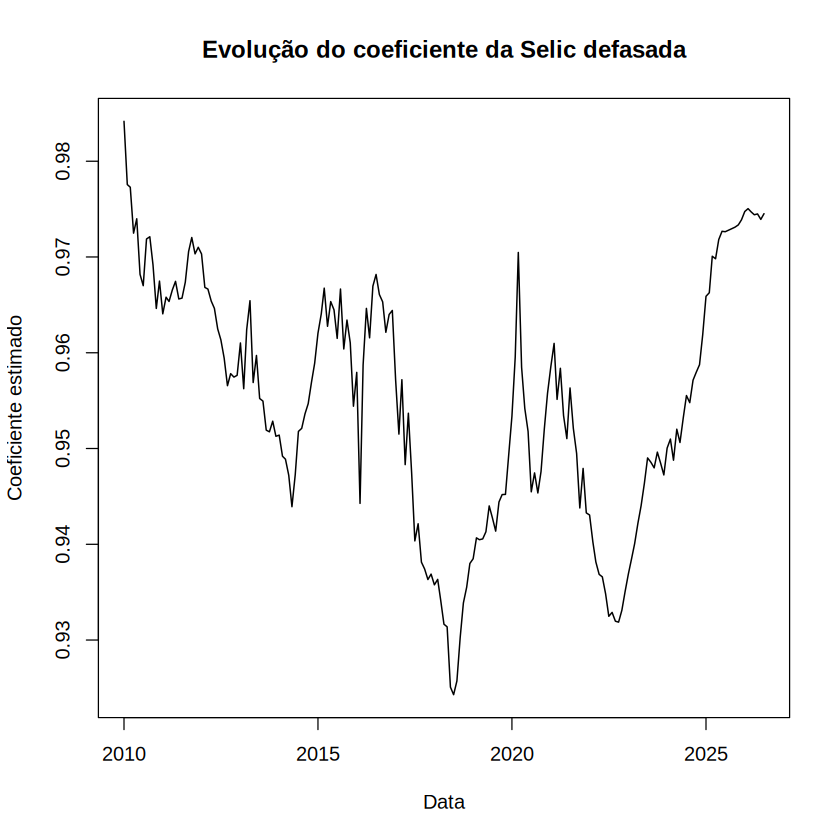

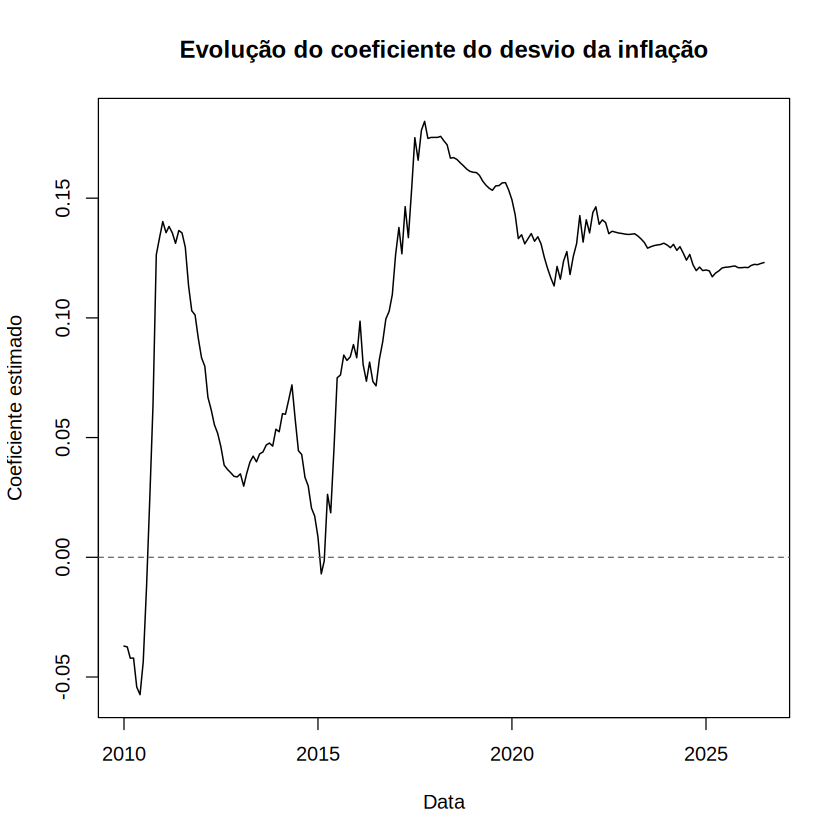

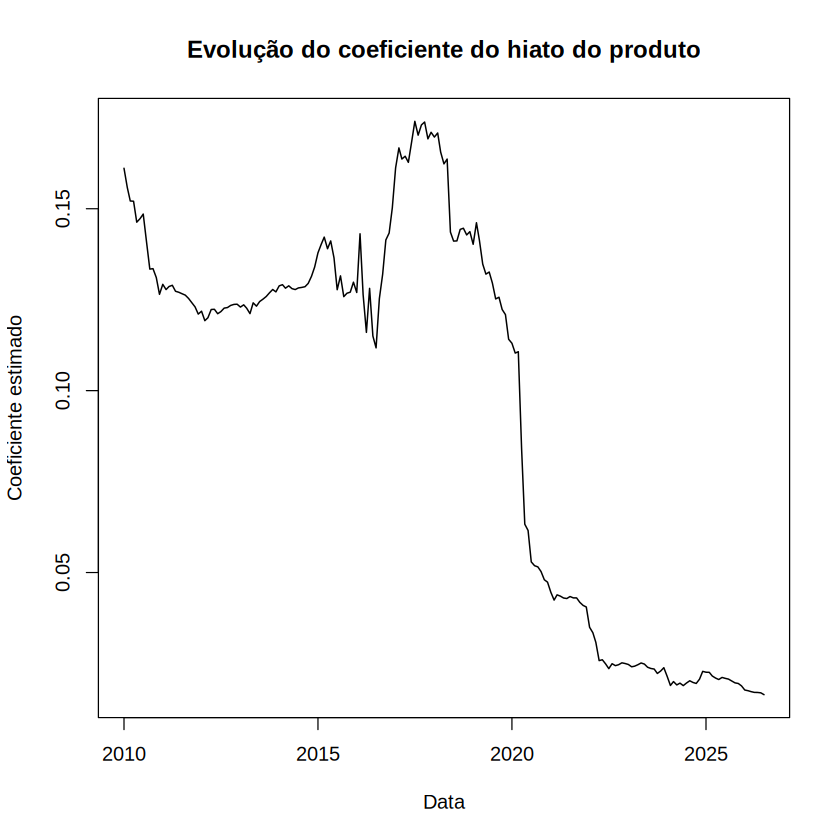

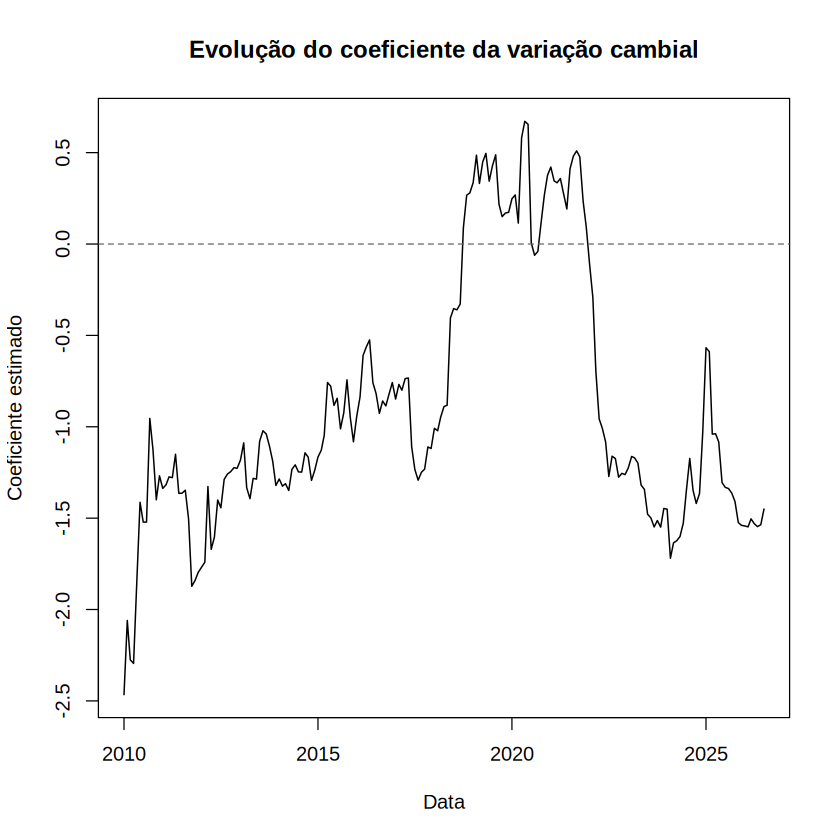

In [ ]:

# ============================================================
# MODELO 2 — GRÁFICOS DOS COEFICIENTES AUXILIARES
# ============================================================

grafico_janela_m2 <- function(coluna, titulo) {

  y <- resultados_janelas_m2[[coluna]]

  plot(
    resultados_janelas_m2$Data,
    y,
    type = "l",
    lwd = 1.2,
    col = "black",
    main = titulo,
    xlab = "Data",
    ylab = "Coeficiente estimado"
  )

  if (min(y) <= 0 && max(y) >= 0) {
    abline(h = 0, lty = 2, col = "gray40")
  }
}

grafico_janela_m2(
  "beta_selic",
  "Evolução do coeficiente da Selic defasada"
)

grafico_janela_m2(
  "beta_inflacao",
  "Evolução do coeficiente do desvio da inflação"
)

grafico_janela_m2(
  "beta_hiato",
  "Evolução do coeficiente do hiato do produto"
)

grafico_janela_m2(
  "beta_cambio",
  "Evolução do coeficiente da variação cambial"
)



========== QLR / SUP-F — MODELO 2 ==========

	supF test

data:  fstats_m2
sup.F = 115.05, p-value < 2.2e-16


========== LOCALIZAÇÃO DA QUEBRA CANDIDATA ==========
Maior estatística F: 115.051 
Observação final do primeiro regime: 42 
Último mês do primeiro regime: 07/2006 
Primeiro mês do segundo regime: 08/2006 
Número de estatísticas calculadas: 198 


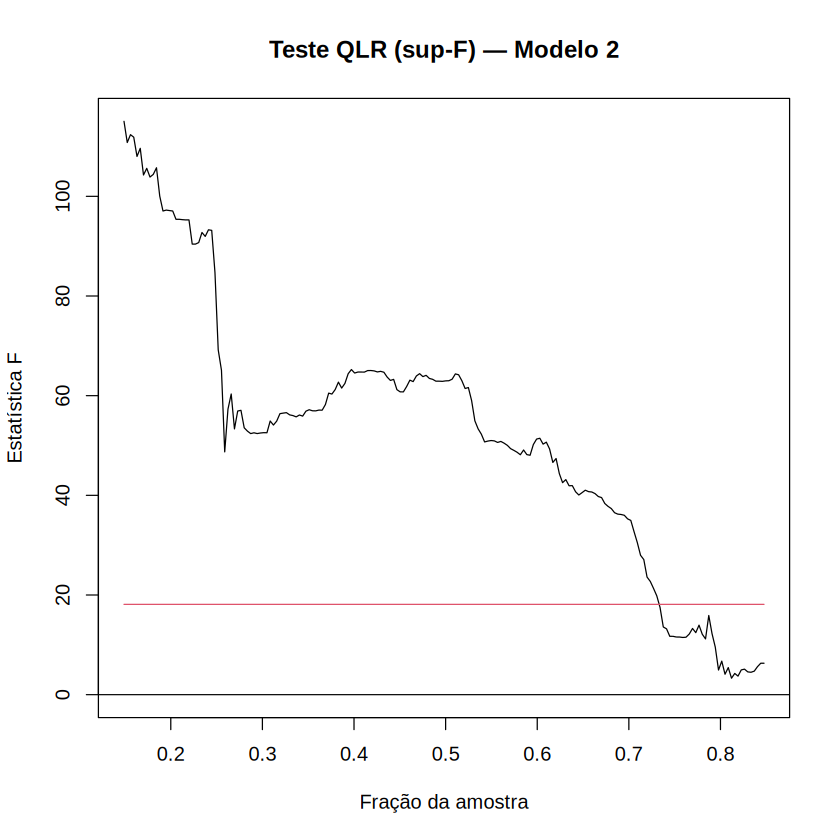

In [ ]:

# ============================================================
# MODELO 2 — TESTE QLR / SUP-F
# ============================================================

# O pacote strucchange já foi instalado na célula 1.

stopifnot(
  nrow(dados_modelo2) == 282,
  nobs(modelo2) == 282,
  length(coef(modelo2)) == 5,
  all(complete.cases(dados_modelo2))
)

# Estatísticas F para possíveis datas de quebra
# Mantemos o trimming de 15% do Modelo 1.

fstats_m2 <- strucchange::Fstats(
  formula_m2,
  data = dados_modelo2,
  from = 0.15,
  to = 0.85
)

# Teste sup-F
resultado_qlr_m2 <- strucchange::sctest(
  fstats_m2,
  type = "supF"
)

cat("\n========== QLR / SUP-F — MODELO 2 ==========\n")
print(resultado_qlr_m2)

# Localização da maior estatística
valores_F_m2 <- as.numeric(fstats_m2$Fstats)
indice_max_m2 <- which.max(valores_F_m2)

# Converter índice temporal interno em observação
obs_quebra_m2 <- as.integer(round(
  as.numeric(time(fstats_m2$Fstats))[indice_max_m2] *
    nrow(dados_modelo2)
))

stopifnot(
  length(obs_quebra_m2) == 1,
  obs_quebra_m2 >= 1,
  obs_quebra_m2 < nrow(dados_modelo2)
)

cat("\n========== LOCALIZAÇÃO DA QUEBRA CANDIDATA ==========\n")
cat("Maior estatística F:",
    valores_F_m2[indice_max_m2], "\n")

cat("Observação final do primeiro regime:",
    obs_quebra_m2, "\n")

cat("Último mês do primeiro regime:",
    format(dados_modelo2$Data[obs_quebra_m2], "%m/%Y"),
    "\n")

cat("Primeiro mês do segundo regime:",
    format(dados_modelo2$Data[obs_quebra_m2 + 1], "%m/%Y"),
    "\n")

cat("Número de estatísticas calculadas:",
    length(valores_F_m2), "\n")

# Gráfico
plot(
  fstats_m2,
  main = "Teste QLR (sup-F) — Modelo 2",
  xlab = "Fração da amostra",
  ylab = "Estatística F"
)


In [ ]:

# ============================================================
# MODELO 2 — BAI-PERRON
# SELEÇÃO DE QUEBRAS PELO BIC
# ============================================================

stopifnot(
  nrow(dados_modelo2) == 282,
  nobs(modelo2) == 282
)

bp_m2 <- strucchange::breakpoints(
  formula_m2,
  data = dados_modelo2,
  h = 0.15,
  breaks = 5
)

cat("\n========== RESUMO BAI-PERRON ==========\n")
print(summary(bp_m2))

# Extrair o BIC diretamente do objeto completo,
# incluindo a especificação sem quebras.

bic_m2 <- as.numeric(BIC(bp_m2))

stopifnot(
  length(bic_m2) == 6,
  all(is.finite(bic_m2))
)

tabela_bic_m2 <- data.frame(
  Numero_quebras = 0:5,
  BIC = bic_m2
)

numero_otimo_m2 <- which.min(bic_m2) - 1L

cat("\n========== BIC — MODELO 2 ==========\n")
print(
  transform(
    tabela_bic_m2,
    BIC = round(BIC, 4)
  ),
  row.names = FALSE
)

cat("\nNúmero ótimo de quebras:",
    numero_otimo_m2, "\n")

# Gráfico de seleção
plot(
  tabela_bic_m2$Numero_quebras,
  tabela_bic_m2$BIC,
  type = "b",
  pch = 19,
  col = "black",
  xlab = "Número de quebras",
  ylab = "BIC",
  main = "Seleção de quebras pelo BIC — Modelo 2"
)

# Recuperar as datas das quebras selecionadas
if (numero_otimo_m2 > 0) {

  bp_selecionado_m2 <- strucchange::breakpoints(
    bp_m2,
    breaks = numero_otimo_m2
  )

  observacoes_quebra_m2 <- as.integer(
    bp_selecionado_m2$breakpoints
  )

  tabela_quebras_m2 <- data.frame(
    Observacao = observacoes_quebra_m2,
    Ultimo_mes_regime = format(
      dados_modelo2$Data[observacoes_quebra_m2],
      "%m/%Y"
    ),
    Primeiro_mes_regime_seguinte = format(
      dados_modelo2$Data[observacoes_quebra_m2 + 1L],
      "%m/%Y"
    )
  )

  cat("\n========== QUEBRAS SELECIONADAS ==========\n")
  print(tabela_quebras_m2, row.names = FALSE)

} else {

  cat("\nO BIC selecionou um modelo sem quebras.\n")

}



========== RESUMO BAI-PERRON ==========

	 Optimal (m+1)-segment partition: 

Call:
breakpoints.formula(formula = formula_m2, h = 0.15, breaks = 5, 
    data = dados_modelo2)

Breakpoints at observation number:
                          
m = 1   42                
m = 2   42     170        
m = 3   42 109     177    
m = 4   42 109     177 230
m = 5   42 109 151 194 238

Corresponding to breakdates:
                                                                               
m = 1   0.148936170212766                                                      
m = 2   0.148936170212766                   0.602836879432624                  
m = 3   0.148936170212766 0.386524822695035                   0.627659574468085
m = 4   0.148936170212766 0.386524822695035                   0.627659574468085
m = 5   0.148936170212766 0.386524822695035 0.535460992907801 0.687943262411348
                         
m = 1                    
m = 2                    
m = 3                    
m = 4   0.81

ERROR: Error: length(bic_m2) == 6 is not TRUE



========== BIC CORRIGIDO — MODELO 2 ==========
 Numero_quebras      BIC
              0 332.1200
              1 266.4947
              2 273.2356
              3 286.6565
              4 305.0537
              5 334.2093

Número ótimo de quebras: 1 

========== QUEBRAS SELECIONADAS ==========
 Observacao Ultimo_mes_regime Primeiro_mes_regime_seguinte
         42           07/2006                      08/2006


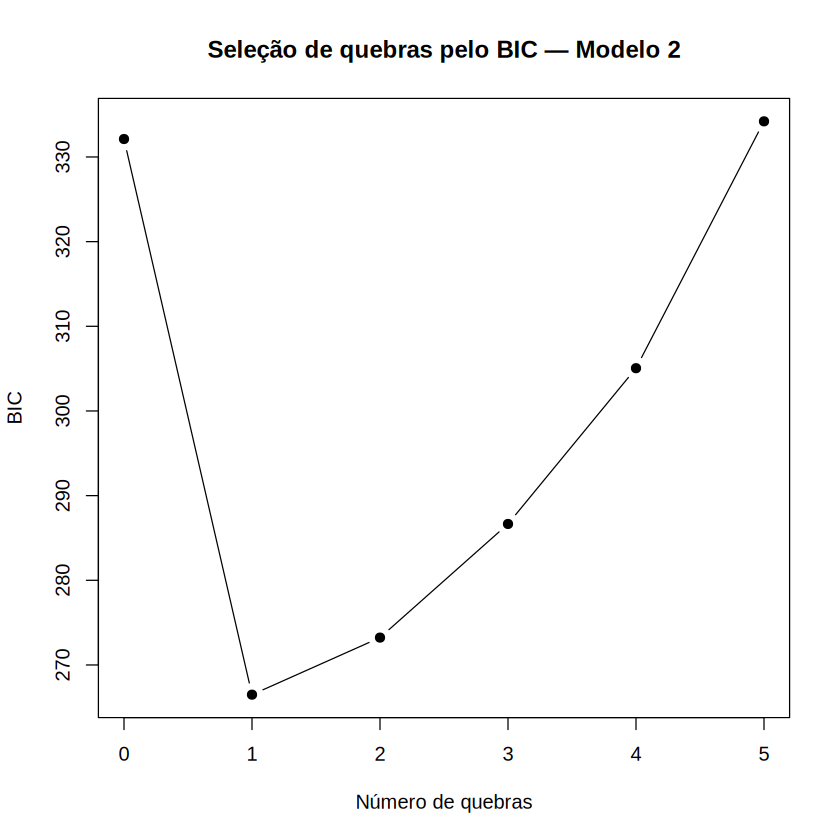

In [ ]:

# ============================================================
# MODELO 2 — BIC CORRIGIDO
# ============================================================

# Matriz de critérios de informação do objeto breakpoints
matriz_bic_m2 <- summary(bp_m2)$RSS

# A linha "BIC" contém os critérios para 0 a 5 quebras
bic_m2 <- as.numeric(matriz_bic_m2["BIC", ])

stopifnot(
  length(bic_m2) == 6,
  all(is.finite(bic_m2))
)

tabela_bic_m2 <- data.frame(
  Numero_quebras = 0:5,
  BIC = bic_m2
)

numero_otimo_m2 <- which.min(bic_m2) - 1L

cat("\n========== BIC CORRIGIDO — MODELO 2 ==========\n")
print(
  transform(tabela_bic_m2, BIC = round(BIC, 4)),
  row.names = FALSE
)

cat("\nNúmero ótimo de quebras:",
    numero_otimo_m2, "\n")

plot(
  tabela_bic_m2$Numero_quebras,
  tabela_bic_m2$BIC,
  type = "b",
  pch = 19,
  col = "black",
  xlab = "Número de quebras",
  ylab = "BIC",
  main = "Seleção de quebras pelo BIC — Modelo 2"
)

if (numero_otimo_m2 > 0) {

  bp_selecionado_m2 <- strucchange::breakpoints(
    bp_m2,
    breaks = numero_otimo_m2
  )

  observacoes_quebra_m2 <- as.integer(
    bp_selecionado_m2$breakpoints
  )

  tabela_quebras_m2 <- data.frame(
    Observacao = observacoes_quebra_m2,
    Ultimo_mes_regime = format(
      dados_modelo2$Data[observacoes_quebra_m2],
      "%m/%Y"
    ),
    Primeiro_mes_regime_seguinte = format(
      dados_modelo2$Data[observacoes_quebra_m2 + 1L],
      "%m/%Y"
    )
  )

  cat("\n========== QUEBRAS SELECIONADAS ==========\n")
  print(tabela_quebras_m2, row.names = FALSE)
}


In [ ]:

# ============================================================
# MODELO 2 — ESTIMAÇÃO DOS REGIMES BAI-PERRON
# ============================================================

# 1. Identificar a quebra selecionada
quebra_m2 <- as.integer(bp_selecionado_m2$breakpoints)

stopifnot(
  length(quebra_m2) == 1,
  !is.na(quebra_m2),
  quebra_m2 == 42
)

# 2. Separar os regimes
dados_regime1_m2 <- dados_modelo2[1:quebra_m2, ]
dados_regime2_m2 <- dados_modelo2[
  (quebra_m2 + 1):nrow(dados_modelo2),
]

stopifnot(
  nrow(dados_regime1_m2) == 42,
  nrow(dados_regime2_m2) == 240
)

# 3. Função para estimar e recuperar parâmetros
estimar_regime_m2 <- function(dados, nome_regime) {

  modelo <- lm(formula_m2, data = dados)

  V <- sandwich::NeweyWest(
    modelo,
    lag = NULL,
    prewhite = FALSE,
    adjust = TRUE
  )

  teste_auxiliar <- lmtest::coeftest(
    modelo,
    vcov. = V
  )

  b <- coef(modelo)
  rho <- unname(b["Selic_L1"])
  d <- 1 - rho

  if (abs(d) < 1e-8) {
    stop("Rho muito próximo de 1 em ", nome_regime)
  }

  # Parâmetros estruturais
  parametros <- c(
    alpha = unname(b["(Intercept)"]),
    rho = rho,
    phi_pi = unname(b["Desvio_Inflacao_L1"]) / d,
    phi_y = unname(b["Hiato_IBC_L1"]) / d,
    phi_e = unname(b["Variacao_Cambio_L1"]) / d
  )

  # Jacobiana para o método delta
  J <- matrix(
    0,
    nrow = length(parametros),
    ncol = length(b),
    dimnames = list(names(parametros), names(b))
  )

  J["alpha", "(Intercept)"] <- 1
  J["rho", "Selic_L1"] <- 1

  correspondencias <- c(
    phi_pi = "Desvio_Inflacao_L1",
    phi_y = "Hiato_IBC_L1",
    phi_e = "Variacao_Cambio_L1"
  )

  for (par in names(correspondencias)) {
    variavel <- correspondencias[[par]]

    J[par, "Selic_L1"] <- unname(b[variavel]) / d^2
    J[par, variavel] <- 1 / d
  }

  # Matriz de covariância dos parâmetros transformados
  V_estrutural <- J %*% V %*% t(J)

  ep <- sqrt(diag(V_estrutural))
  estatistica_t <- parametros / ep

  valor_p <- 2 * pt(
    abs(estatistica_t),
    df = df.residual(modelo),
    lower.tail = FALSE
  )

  tabela <- data.frame(
    Regime = nome_regime,
    Parametro = names(parametros),
    Estimativa = as.numeric(parametros),
    Erro_padrao_NW = as.numeric(ep),
    Estatistica_t = as.numeric(estatistica_t),
    Valor_p = as.numeric(valor_p)
  )

  stopifnot(
    nrow(tabela) == 5,
    all(is.finite(as.matrix(tabela[, 3:6])))
  )

  list(
    modelo = modelo,
    teste_auxiliar = teste_auxiliar,
    tabela = tabela,
    n = nrow(dados),
    r2 = summary(modelo)$r.squared,
    inicio = min(dados$Data),
    fim = max(dados$Data)
  )
}

# 4. Estimar os dois regimes
regime1_m2 <- estimar_regime_m2(
  dados_regime1_m2,
  "Regime 1"
)

regime2_m2 <- estimar_regime_m2(
  dados_regime2_m2,
  "Regime 2"
)

# 5. Consolidar parâmetros estruturais
tabela_regimes_m2 <- rbind(
  regime1_m2$tabela,
  regime2_m2$tabela
)

cat("\n========== PARÂMETROS ESTRUTURAIS ==========\n")

print(
  transform(
    tabela_regimes_m2,
    Estimativa = round(Estimativa, 5),
    Erro_padrao_NW = round(Erro_padrao_NW, 5),
    Estatistica_t = round(Estatistica_t, 4),
    Valor_p = signif(Valor_p, 5)
  ),
  row.names = FALSE
)

# 6. Informações das subamostras
cat("\n========== INFORMAÇÕES DOS REGIMES ==========\n")

for (regime in list(regime1_m2, regime2_m2)) {
  cat(
    format(regime$inicio, "%m/%Y"),
    "a",
    format(regime$fim, "%m/%Y"),
    "| N =", regime$n,
    "| R² =", round(regime$r2, 4),
    "\n"
  )
}

# 7. Coeficientes auxiliares
cat("\n========== REGIME 1: COEFICIENTES AUXILIARES ==========\n")
print(regime1_m2$teste_auxiliar)

cat("\n========== REGIME 2: COEFICIENTES AUXILIARES ==========\n")
print(regime2_m2$teste_auxiliar)



========== PARÂMETROS ESTRUTURAIS ==========
   Regime Parametro Estimativa Erro_padrao_NW Estatistica_t     Valor_p
 Regime 1     alpha   -1.25761        0.57459       -2.1887  3.5007e-02
 Regime 1       rho    1.08526        0.03553       30.5464  7.5629e-28
 Regime 1    phi_pi    2.57920        0.64964        3.9702  3.1825e-04
 Regime 1     phi_y   -4.52365        2.18702       -2.0684  4.5644e-02
 Regime 1     phi_e   74.75157       32.67563        2.2877  2.7969e-02
 Regime 2     alpha    0.17863        0.08836        2.0216  4.4353e-02
 Regime 2       rho    0.96794        0.00876      110.4492 1.5982e-204
 Regime 2    phi_pi    3.30895        0.82187        4.0261  7.6545e-05
 Regime 2     phi_y    2.33193        0.86591        2.6930  7.5902e-03
 Regime 2     phi_e  -21.71438       15.16925       -1.4315  1.5362e-01

========== INFORMAÇÕES DOS REGIMES ==========
02/2003 a 07/2006 | N = 42 | R² = 0.9876 
08/2006 a 07/2026 | N = 240 | R² = 0.9902 

========== REGIME 1: COEFICIE

In [ ]:

# ============================================================
# MODELO 2 — TESTES DE CHOW
# DATAS INSTITUCIONAIS
# ============================================================

datas_chow_m2 <- data.frame(
  Presidente = c(
    "Alexandre Tombini",
    "Ilan Goldfajn",
    "Roberto Campos Neto",
    "Gabriel Galipolo"
  ),
  Inicio = as.Date(c(
    "2011-01-01",
    "2016-06-01",
    "2019-03-01",
    "2025-01-01"
  ))
)

teste_chow_m2 <- function(data_quebra, presidente) {

  antes <- dados_modelo2[
    dados_modelo2$Data < data_quebra, ,
    drop = FALSE
  ]

  depois <- dados_modelo2[
    dados_modelo2$Data >= data_quebra, ,
    drop = FALSE
  ]

  n1 <- nrow(antes)
  n2 <- nrow(depois)

  # Cinco parâmetros, incluindo o intercepto
  k <- length(coef(modelo2))

  if (n1 <= k || n2 <= k) {
    stop("Observações insuficientes: ", presidente)
  }

  modelo_antes <- lm(formula_m2, data = antes)
  modelo_depois <- lm(formula_m2, data = depois)

  # Garantir que todos os coeficientes foram estimados
  stopifnot(
    !anyNA(coef(modelo_antes)),
    !anyNA(coef(modelo_depois))
  )

  rss_restrito <- sum(resid(modelo2)^2)

  rss_irrestrito <- sum(resid(modelo_antes)^2) +
    sum(resid(modelo_depois)^2)

  gl1 <- k
  gl2 <- n1 + n2 - 2 * k

  F_chow <- (
    (rss_restrito - rss_irrestrito) / gl1
  ) / (
    rss_irrestrito / gl2
  )

  valor_p <- pf(
    F_chow,
    df1 = gl1,
    df2 = gl2,
    lower.tail = FALSE
  )

  data.frame(
    Presidente = presidente,
    Data = format(data_quebra, "%m/%Y"),
    N_antes = n1,
    N_depois = n2,
    F = F_chow,
    Valor_p = valor_p,
    Significativo_5pct = valor_p < 0.05
  )
}

resultados_chow_m2 <- do.call(
  rbind,
  lapply(seq_len(nrow(datas_chow_m2)), function(i) {
    teste_chow_m2(
      datas_chow_m2$Inicio[i],
      datas_chow_m2$Presidente[i]
    )
  })
)

stopifnot(
  nrow(resultados_chow_m2) == 4,
  all(resultados_chow_m2$N_antes +
      resultados_chow_m2$N_depois == 282),
  all(is.finite(resultados_chow_m2$F)),
  all(is.finite(resultados_chow_m2$Valor_p))
)

cat("\n========== TESTES DE CHOW — MODELO 2 ==========\n")

print(
  transform(
    resultados_chow_m2,
    F = round(F, 4),
    Valor_p = signif(Valor_p, 5)
  ),
  row.names = FALSE
)



========== TESTES DE CHOW — MODELO 2 ==========
          Presidente    Data N_antes N_depois       F    Valor_p
   Alexandre Tombini 01/2011      95      187 11.1493 8.7068e-10
       Ilan Goldfajn 06/2016     160      122 10.0061 8.3680e-09
 Roberto Campos Neto 03/2019     193       89  7.3029 1.9375e-06
    Gabriel Galipolo 01/2025     263       19  2.6464 2.3464e-02
 Significativo_5pct
               TRUE
               TRUE
               TRUE
               TRUE
